In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

project_root = Path.cwd().parent
sys.path.append(str(project_root))

from src.data_prep import load_flight_data

In [ ]:
df = load_flight_data(
    "../data/raw/air traffic-selected-columns.csv"
)

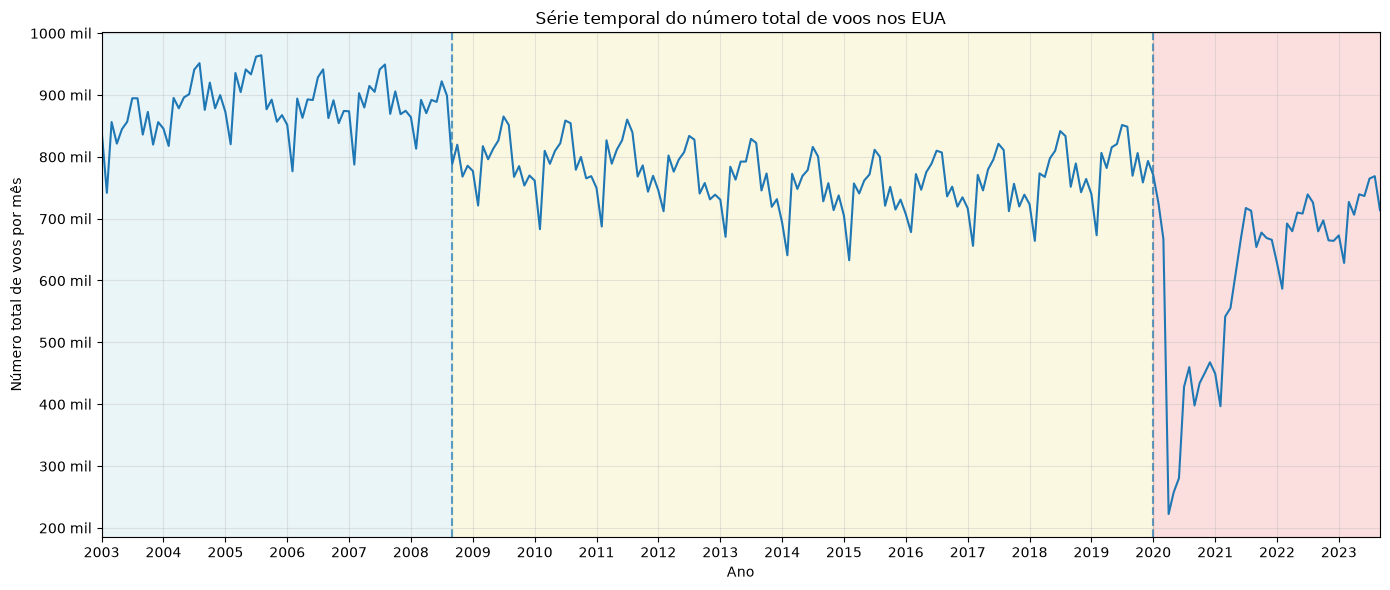

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter


def thousands_formatter(x, pos):
    return f"{x/1000:.0f} mil"


plt.figure(figsize=(14, 6))

ax = plt.gca()

# Faixas de fundo
ax.axvspan(
    pd.Timestamp("2003-01-01"),
    pd.Timestamp("2008-08-31"),
    color="lightblue",
    alpha=0.25
)

ax.axvspan(
    pd.Timestamp("2008-09-01"),
    pd.Timestamp("2019-12-31"),
    color="khaki",
    alpha=0.25
)

ax.axvspan(
    pd.Timestamp("2020-01-01"),
    pd.Timestamp("2023-09-30"),
    color="lightcoral",
    alpha=0.25
)

# Série temporal
ax.plot(
    df["Date"],
    df["Flt"],
    linewidth=1.5
)

# Linhas de transição
ax.axvline(
    pd.Timestamp("2008-09-01"),
    linestyle="--",
    alpha=0.7
)

ax.axvline(
    pd.Timestamp("2020-01-01"),
    linestyle="--",
    alpha=0.7
)

# Formatação do eixo Y
ax.yaxis.set_major_formatter(
    FuncFormatter(thousands_formatter)
)

# Formatação do eixo X
ax.xaxis.set_major_locator(
    mdates.YearLocator(1)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

plt.title("Série temporal do número total de voos nos EUA")
plt.xlabel("Ano")
plt.ylabel("Número total de voos por mês")

plt.xlim(df["Date"].min(), df["Date"].max())

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()